In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

In [31]:
df=pd.read_csv('diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [32]:
df.duplicated().sum()

0

In [33]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

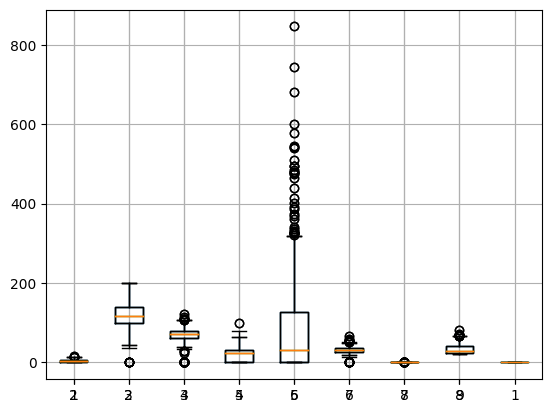

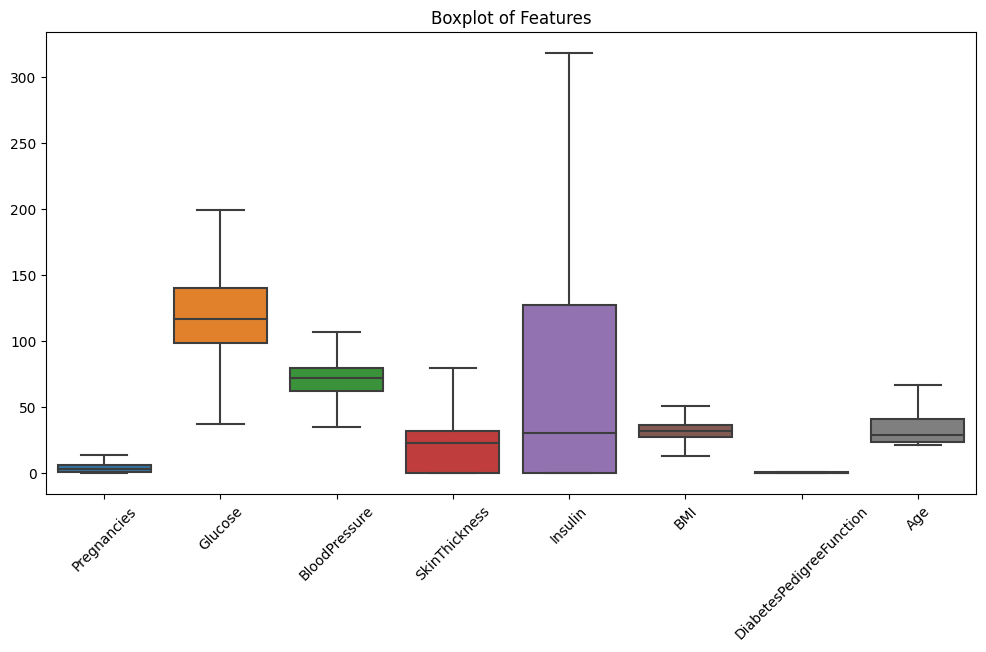

In [35]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=features)

plt.xticks(rotation=45)
plt.title("Boxplot of Features")
plt.show()

In [36]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [37]:
target=df[['Outcome']]
features=df.drop(columns=['Outcome'])

In [38]:

def outlier_capping(df,column):

    Q1= df[column].quantile(0.25)

    Q3= df[column].quantile(0.75)

    IQR= Q3-Q1

    lower_extreme= Q1-1.5*IQR

    upper_extreme= Q3+1.5*IQR

    df[column]= df[column].apply(lambda x: lower_extreme if x< lower_extreme else upper_extreme if x>upper_extreme else x)

for col in features.select_dtypes(include=['int','float']).columns:

    outlier_capping(features,col)

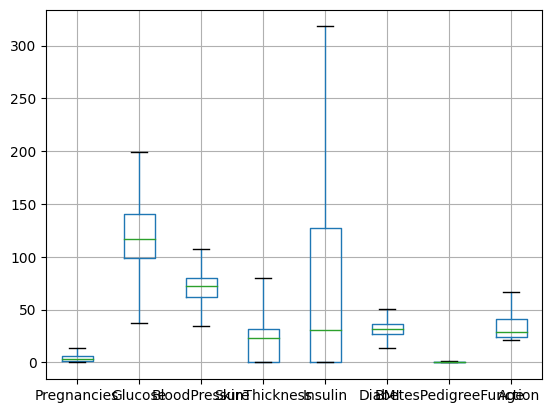

In [39]:
features.boxplot()
plt.show()

In [40]:
from sklearn.feature_selection import f_classif

c:\Users\udayk\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\utils\validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


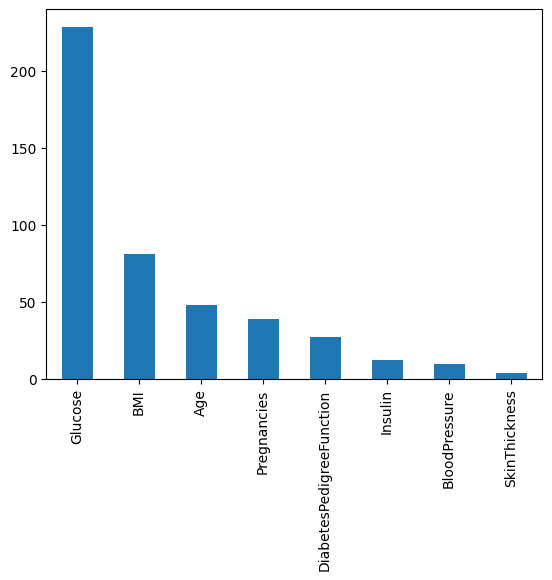

In [41]:
f_clas= f_classif(features,target)
pd.Series(f_clas[0],index=features.columns).sort_values(ascending=False).plot(kind='bar')
plt.show()

In [42]:
x_train,x_test,y_train,y_test= train_test_split(features,target,train_size=0.8,random_state=100)

print(x_train.shape)

print(x_test.shape)

print(y_train.shape)

print(y_test.shape)

(614, 8)
(154, 8)
(614, 1)
(154, 1)


In [43]:
x_train.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
660,10.0,162.0,84.0,0.0,0.0,27.7,0.182,54.0
69,4.0,146.0,85.0,27.0,100.0,28.9,0.189,27.0
85,2.0,110.0,74.0,29.0,125.0,32.4,0.698,27.0
219,5.0,112.0,66.0,0.0,0.0,37.8,0.261,41.0
712,10.0,129.0,62.0,36.0,0.0,41.2,0.441,38.0


In [46]:
log_model = LogisticRegression()

log_model.fit(x_train, y_train.values.ravel())

LogisticRegression()

In [48]:
y_pred = log_model.predict(x_test)

y_pred[:10]

array([0, 0, 1, 0, 0, 1, 1, 0, 1, 0], dtype=int64)

In [50]:
accuracy_score(y_test, y_pred)

0.7337662337662337

In [51]:
y_train_pred = log_model.predict(x_train)

accuracy_score(y_train, y_train_pred)

0.7915309446254072

In [ ]:

y_pred1=log_model.predict(x_test)

accuracy_score(y_test,y_pred1)

0.7337662337662337

In [53]:
log_model.predict_proba(x_test)


array([[0.81133233, 0.18866767],
       [0.93840536, 0.06159464],
       [0.25138142, 0.74861858],
       [0.89462356, 0.10537644],
       [0.57623896, 0.42376104],
       [0.2758933 , 0.7241067 ],
       [0.03572308, 0.96427692],
       [0.87483836, 0.12516164],
       [0.08542642, 0.91457358],
       [0.77062514, 0.22937486],
       [0.91247772, 0.08752228],
       [0.11061785, 0.88938215],
       [0.40821075, 0.59178925],
       [0.68596431, 0.31403569],
       [0.25878869, 0.74121131],
       [0.71167737, 0.28832263],
       [0.91993746, 0.08006254],
       [0.75755359, 0.24244641],
       [0.43830782, 0.56169218],
       [0.85353626, 0.14646374],
       [0.75963842, 0.24036158],
       [0.98868426, 0.01131574],
       [0.43823737, 0.56176263],
       [0.01797024, 0.98202976],
       [0.73935953, 0.26064047],
       [0.14398699, 0.85601301],
       [0.49835942, 0.50164058],
       [0.68868457, 0.31131543],
       [0.60169431, 0.39830569],
       [0.41197116, 0.58802884],
       [0.

In [54]:
sigmoid=log_model.predict_proba(x_test)[:,1]

In [55]:
from sklearn.metrics import log_loss

log_loss(y_test, sigmoid)

0.5480629188367733

In [56]:
from sklearn.metrics import classification_report,confusion_matrix

In [57]:
y_pred2=[1 if x>=0.55 else 0 for x in sigmoid]

In [58]:
conf=confusion_matrix(y_test,y_pred2)
conf

array([[87, 14],
       [27, 26]], dtype=int64)

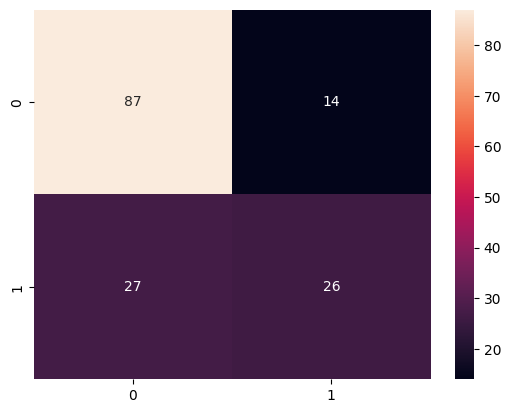

In [59]:
sns.heatmap(conf,annot=True)
plt.show()

In [60]:
print(classification_report(y_test,y_pred2))

              precision    recall  f1-score   support

           0       0.76      0.86      0.81       101
           1       0.65      0.49      0.56        53

    accuracy                           0.73       154
   macro avg       0.71      0.68      0.68       154
weighted avg       0.72      0.73      0.72       154



In [61]:
from sklearn.metrics import roc_auc_score,roc_curve

In [62]:
auc_score=roc_auc_score(y_test,sigmoid)

auc_score

0.7788156174107976

In [63]:
fpr,tpr,thr=roc_curve(y_test,sigmoid)





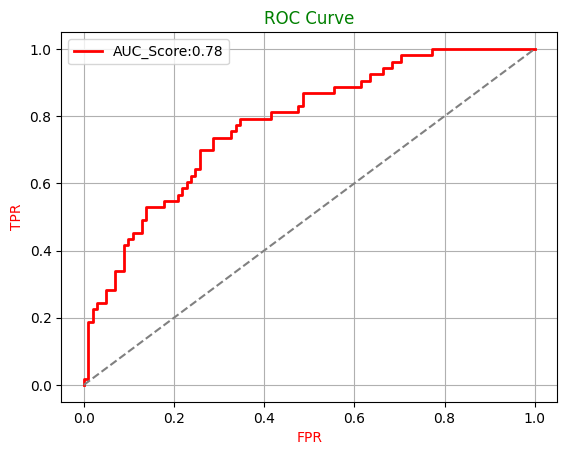

In [64]:
plt.plot(fpr,tpr,lw=2,color='red',label=f'AUC_Score:{auc_score:.2f}')

plt.plot([0,1],linestyle='--',color='grey')

plt.title('ROC Curve',color='green',size=12)

plt.xlabel('FPR',color='red',size=10)

plt.ylabel('TPR',color='red',size=10)

plt.legend()

plt.grid()

plt.show()

In [65]:
coefficients = pd.DataFrame({
    'Feature': features.columns,
    'Coefficient': log_model.coef_[0]
})

coefficients.sort_values(by='Coefficient', ascending=False)

,Feature,Coefficient
1,Glucose,1.175519
5,BMI,0.736665
6,DiabetesPedigreeFunction,0.451488
0,Pregnancies,0.348176
7,Age,0.230773
4,Insulin,-0.081537
3,SkinThickness,-0.091955
2,BloodPressure,-0.145116


In [66]:
coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()

coefficients.sort_values(by='Abs_Coefficient', ascending=False)

,Feature,Coefficient,Abs_Coefficient
1,Glucose,1.175519,1.175519
5,BMI,0.736665,0.736665
6,DiabetesPedigreeFunction,0.451488,0.451488
0,Pregnancies,0.348176,0.348176
7,Age,0.230773,0.230773
2,BloodPressure,-0.145116,0.145116
3,SkinThickness,-0.091955,0.091955
4,Insulin,-0.081537,0.081537


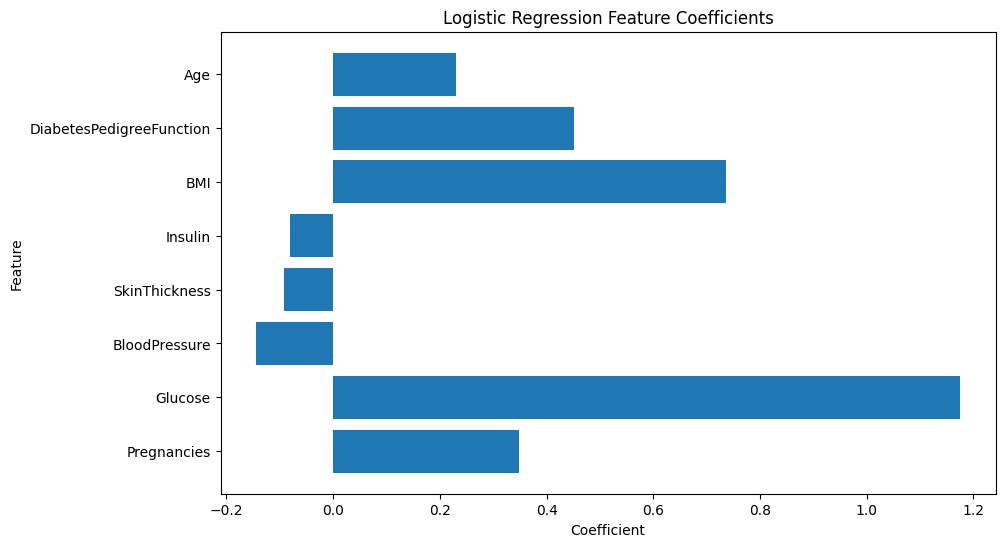

In [67]:
plt.figure(figsize=(10, 6))

plt.barh(coefficients['Feature'], coefficients['Coefficient'])

plt.xlabel('Coefficient')
plt.ylabel('Feature')
plt.title('Logistic Regression Feature Coefficients')

plt.show()

In [68]:
import pickle

with open('logistic_model.pkl', 'wb') as file:
    pickle.dump(log_model, file)

with open('scaler.pkl', 'wb') as file:
    pickle.dump(std_sca, file)